# Predicting the 2026 FIFA World Cup with a Dixon-Coles model

This notebook is the narrative companion to the project. It walks through the
full analysis end to end: the data, the goal model, how well it is calibrated,
and the resulting 2026 title odds.

**The idea.** Every match is a pair of Poisson-distributed goal counts. Each
team gets an *attack* and a *defence* rating estimated jointly from a century of
World Cup results, with recent tournaments weighted more heavily and a
Dixon-Coles correction for low-scoring games. Feeding those ratings into a
Monte Carlo simulation of the 48-team bracket turns them into probabilities.

The reusable logic lives in the `worldcup` package (`src/worldcup`); here we
just orchestrate it and look at the output.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "src"))

from worldcup import config, simulation
from worldcup.model import fit_dixon_coles

BLUE, MUTED, GRID, SURFACE, INK = "#2a78d6", "#898781", "#e1e0d9", "#fcfcfb", "#0b0b0b"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.grid": False, "font.size": 10})

## 1. The data

The training set is every World Cup match with a recorded scoreline from 1930 to
2018 (the versioned snapshot in `data/raw`, cleaned into `data/processed`).
Predecessor states are folded into their modern successors so, for example,
Germany inherits West Germany's record.

In [2]:
matches = pd.read_csv(config.CLEAN_HISTORICAL)
print(f"{len(matches)} matches, {matches['Year'].min()}-{matches['Year'].max()}, "
      f"{pd.concat([matches['HomeTeam'], matches['AwayTeam']]).nunique()} teams")
matches.head()

864 matches, 1930-2018, 78 teams


,HomeTeam,AwayTeam,Year,HomeGoals,AwayGoals
0,France,Mexico,1930,4,1
1,Argentina,France,1930,1,0
2,Chile,Mexico,1930,3,0
3,Chile,France,1930,1,0
4,Argentina,Mexico,1930,6,3


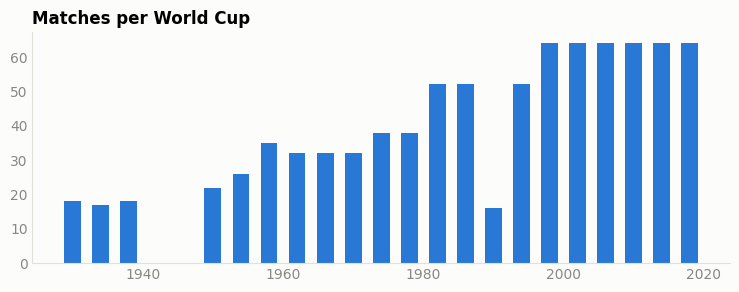

In [3]:
per_year = matches.groupby("Year").size()
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(per_year.index, per_year.values, color=BLUE, width=2.4)
ax.set_title("Matches per World Cup", loc="left", fontweight="bold")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.tick_params(length=0, colors=MUTED)
plt.show()

A quick look at scoring: the home (first-listed) side scores slightly more on
average, but World Cup fixtures are mostly neutral, so this edge is small, and the
model estimates it rather than assuming it.

In [4]:
avg_home = matches["HomeGoals"].mean()
avg_away = matches["AwayGoals"].mean()
print(f"Average goals - first-listed team: {avg_home:.2f}, opponent: {avg_away:.2f}")
print(f"Share of draws: {(matches['HomeGoals'] == matches['AwayGoals']).mean():.1%}")

Average goals - first-listed team: 1.80, opponent: 1.05
Share of draws: 22.1%


## 2. The Dixon-Coles model

For a match between home team $i$ and away team $j$:

$$\lambda = \exp(\text{home} + \text{att}_i - \text{def}_j), \qquad
  \mu = \exp(\text{att}_j - \text{def}_i)$$

$$P(x, y) = \tau(x, y;\lambda,\mu,\rho)\; \text{Poisson}(x;\lambda)\;
  \text{Poisson}(y;\mu)$$

where $\tau$ nudges the four low-scoring results the independent Poisson model
gets wrong. We fit it by time-weighted, ridge-regularised maximum likelihood,
using 2026 as the reference date for the decay.

In [5]:
model = fit_dixon_coles(matches, reference_year=2026)
print(f"home advantage = {model.home_advantage:.3f}    rho = {model.rho:.3f}")

net = {t: model.attack[t] + model.defence[t] for t in model.teams}
ranking = pd.DataFrame(
    {"team": list(net), "attack": [model.attack[t] for t in net],
     "defence": [model.defence[t] for t in net],
     "net": list(net.values())}
).sort_values("net", ascending=False).reset_index(drop=True)
ranking.head(10).round(2)

home advantage = 0.260    rho = 0.069


,team,attack,defence,net
0,Germany,0.33,0.14,0.47
1,France,0.20,0.19,0.39
2,Brazil,0.29,0.10,0.39
3,Netherlands,0.21,0.17,0.38
4,Belgium,0.17,0.07,0.24
5,Argentina,0.18,0.06,0.24
6,Croatia,0.20,0.02,0.22
7,England,0.08,0.14,0.21
8,Spain,0.19,0.01,0.20
9,Colombia,0.14,0.06,0.20


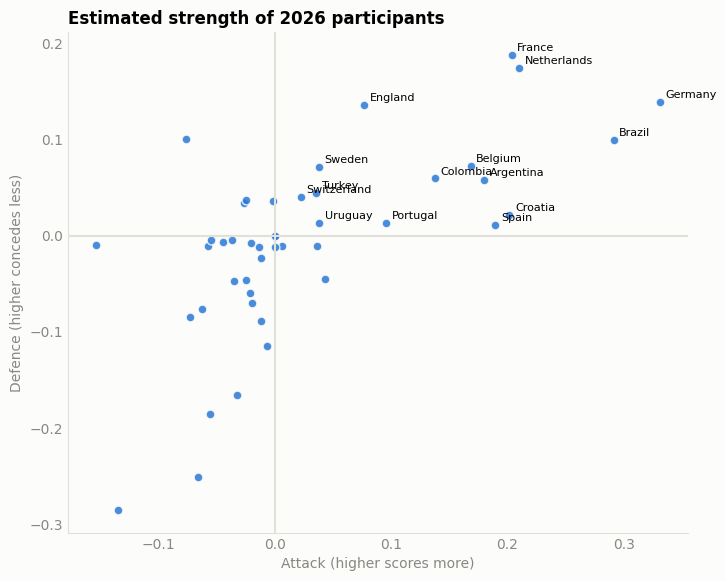

In [6]:
groups = pd.read_csv(config.CLEAN_GROUPS_2026)
teams26 = list(groups["team"])
att = np.array([model.attack.get(t, 0.0) for t in teams26])
dfn = np.array([model.defence.get(t, 0.0) for t in teams26])

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.axhline(0, color=GRID); ax.axvline(0, color=GRID)
ax.scatter(att, dfn, s=40, color=BLUE, alpha=0.85, edgecolor=SURFACE)
for t, a, d in sorted(zip(teams26, att, dfn), key=lambda z: z[1] + z[2], reverse=True)[:15]:
    ax.annotate(t, (a, d), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("Attack (higher scores more)", color=MUTED)
ax.set_ylabel("Defence (higher concedes less)", color=MUTED)
ax.set_title("Estimated strength of 2026 participants", loc="left", fontweight="bold")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.tick_params(length=0, colors=MUTED)
plt.show()

## 3. Does it work? A back-test

The 2026 tournament has been played, so we can check the predictions against
reality. We pool every `(team, stage)` prediction (the probability each team
reaches the round of 32, 16, quarters, semis and final) and compare it with
what actually happened. A well-calibrated model sits on the diagonal.

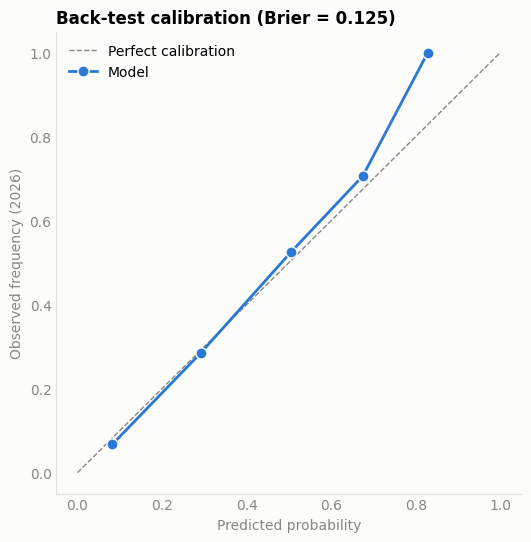

In [7]:
probs = simulation.monte_carlo(groups, model, n_sims=5000)
knockout = pd.read_csv(config.CLEAN_FIXTURE_2026)
actual = simulation.actual_reached_depths(knockout)

stage_cols = [("round_of_32", simulation.R32), ("round_of_16", simulation.R16),
              ("quarter_final", simulation.QUARTER), ("semi_final", simulation.SEMI),
              ("final", simulation.FINAL)]
p, a = [], []
for _, row in probs.iterrows():
    depth = actual.get(row["team"], simulation.GROUP)
    for col, stage in stage_cols:
        p.append(row[col]); a.append(int(depth >= stage))
p, a = np.array(p), np.array(a)
brier = np.mean((p - a) ** 2)

edges = np.linspace(0, 1, 6)
xs = [p[(p >= lo) & (p < hi)].mean() for lo, hi in zip(edges[:-1], edges[1:]) if ((p >= lo) & (p < hi)).any()]
ys = [a[(p >= lo) & (p < hi)].mean() for lo, hi in zip(edges[:-1], edges[1:]) if ((p >= lo) & (p < hi)).any()]

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1, label="Perfect calibration")
ax.plot(xs, ys, "o-", color=BLUE, lw=2, ms=8, markeredgecolor=SURFACE, label="Model")
ax.set_xlabel("Predicted probability", color=MUTED)
ax.set_ylabel("Observed frequency (2026)", color=MUTED)
ax.set_title(f"Back-test calibration (Brier = {brier:.3f})", loc="left", fontweight="bold")
ax.legend(frameon=False)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.tick_params(length=0, colors=MUTED)
plt.show()

## 4. The 2026 predictions

Finally, the headline output: each team's probability of winning the tournament,
from 5,000 simulated brackets.

In [8]:
top = probs.head(15)[["team", "group", "semi_final", "final", "champion"]].copy()
for c in ("semi_final", "final", "champion"):
    top[c] = (top[c] * 100).round(1)
top.reset_index(drop=True)

,team,group,semi_final,final,champion
0,Germany,E,21.2,13.8,8.6
1,France,I,18.1,11.4,6.4
2,Brazil,C,17.8,10.2,6.4
3,Netherlands,F,18.2,11.2,6.2
4,Belgium,G,15.8,8.7,4.6
5,Croatia,L,13.9,7.4,4.1
6,England,L,13.5,6.9,3.8
7,Argentina,J,13.4,6.8,3.5
8,Spain,H,13.6,6.6,3.4
9,Colombia,K,12.8,6.3,3.1


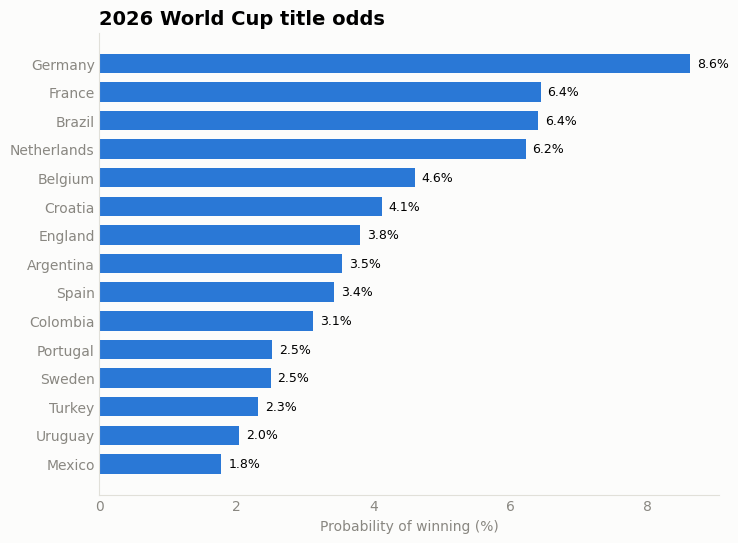

In [9]:
t = probs.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
vals = t["champion"] * 100
ax.barh(t["team"], vals, color=BLUE, height=0.68)
for y, v in enumerate(vals):
    ax.text(v + 0.1, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("Probability of winning (%)", color=MUTED)
ax.set_title("2026 World Cup title odds", loc="left", fontweight="bold", fontsize=14)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.tick_params(length=0, colors=MUTED)
plt.show()

## Takeaways and limitations

- Strength is estimated **jointly and relative to opposition**, not from raw goal
  averages, and regularisation keeps small-sample sides from dominating.
- The back-test shows the probabilities are **reasonably calibrated** on the real
  2026 results.
- **Limitations.** Training data ends in 2018 (recent World Cup pages split match
  data across sub-articles with inconsistent markup), all knockout venues are
  treated as neutral, and squad/injury information is ignored. A natural
  extension is to blend in continental qualifiers and the FIFA ranking as a prior
  for debutant nations.